# Спринт 3 - Проект модуля - нейросеть для классификации таблеток

--
В связи с недостуностью ВМ от Яндекс.Практикум, проект выполнен на собственном локальном компьютере без GPU

## Инициалиация

In [49]:
import random
import pandas as pd
import numpy as np
import pathlib as path
import torch
from dotenv import load_dotenv
import os
import matplotlib.pyplot as plt

load_dotenv()

SEED = 43
# пути

ds = os.getenv('OGYEIV2_DATASET_DEST_DIR', 'data/dataset/parsed') 
DATASET_PATH = path.Path(ds)
DATASET_PATH.mkdir(parents=True, exist_ok=True)

PREPROCESSING_PATH = path.Path('data/preprocessing')
PREPROCESSING_PATH.mkdir(parents=True, exist_ok=True)

MODELS_PATH = path.Path('data/models')
MODELS_PATH.mkdir(parents=True, exist_ok=True)

def init_random():
    """
    Инициализация случайных величин для повторяемости экспериментов
    """   
    torch.random.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)


[Комментарий ревьюера] ✔️
Хорошо.

## Этап 0 - подготовка
см. [readme.md](readme.md) для установки python и зависимостей

## Этап 1 - загрузка и подготовка данных

- Загрузить датасеты для обучения и валидации, определить операции предобработки, подготовить загрузчики `train_loader` и `val_loader`
- Вывести количество классов и изображений в каждом датасете

### Парсинга Kaggle датасета

** Важно: Загрузить архив по предоставленной ссылке на Яндекс Диск не получается (https://disk.yandex.ru/d/o4oQ4Yk7SpH1dw) - 500-ая ошибка.
Поэтому придется использовать оригинальный датасет с Kaggle - https://www.kaggle.com/datasets/richardradli/ogyeiv2/data
Датасет представлен в формате YOLO для задачи сегментации:
- изображение (jpg) в отдельной директории 
- метки класса в отдельной директории, с тем же именем файла (txt), что и изображение 
- файл с меткой содержит саму метку и набор координат (контур полигона), в котором находится объект на изображении.

Для задачи классификации необходимо сначала предобработать датасет для получения классической структуры:
- директория соответсвует названию класса
- внутри директории находятся изображения этого класса, вырезанные из исходно изображения, согласно представленным координатам

#### Посмотрим как выглядит выборочная (1-ая) картинка и каким контуром (сегментом) она задана

In [51]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def parse_and_crop_image(img: Image.Image, label_segment: str, margin = 100):   
    """
    Распарсивает контур объекта на изображении:
    - формирует обрезанное изображение только заданного объекта без лишней информации с исходного изображения
    - добавляет отступ (margin) от края изображения, чтобы захватить немного фона вокруг

    Returns:
        image_crop: Image - обрезанное изображение
        (points_x, points_y): tuple(float[], floatp[]) - точки (координат) контура
        (left, top, right, down): tuple(int, int, int, int) - границы (координаты) рамки вырезания объекта
    """
    
    # parse segment points
    coords = label_segment.split()[1:]
    points_x = [float(x) for x in coords[0::2]]
    points_y = [float(y) for y in coords[1::2]]

    # scale back to original sizes
    W, H = img.width, img.height
    points_x = np.array(points_x) * W
    points_y = np.array(points_y) * H

    # bounding box
    x_min, x_max = min(points_x), max(points_x)
    y_min, y_max = min(points_y), max(points_y)

    # add external margins for visual comfort
    margin = 100    
    left = max(0, x_min - margin)
    right = min(W, x_max + margin)
    top = max(0, y_min - margin)
    down = min(H, y_max + margin)
    image_crop = img.crop(box=(left, top, right, down))

    return image_crop, (points_x, points_y), (left, top, right, down)

def plot_image_from_dataset(img: Image.Image, name:str, label_segment:str, margin = 100):
    """
    Выводит картинку оригинального, а также обрезанное изображение, согласно информации о сегментации картинки
    """
    # parse class label
    label = label_segment.split()[0]
    image_crop, (points_x, points_y), (left, top, right, down) = parse_and_crop_image(img, label_segment, margin)
    
    # prepare plot
    plt.figure(figsize=(10,4))

    # original image
    plt.subplot(1,2,1)
    plt.imshow(img)
    
    # segment contour by points
    plt.plot(points_x, points_y)
    plt.title(f'label = {label} | image = {name}.jpg')

    # plot box
    plt.vlines([left, right], ymin=down, ymax=top, color='green')
    plt.hlines([top, down], xmin=left, xmax=right, color='green')

    x_min, x_max = min(points_x), max(points_x)
    y_min, y_max = min(points_y), max(points_y)
    plt.scatter([x_min, x_max],[y_min, y_max], marker='x')

    plt.legend(['segment (+corners)', f'borders with margins ({margin})'])
    
    # plot cropped image
    plt.subplot(1,2,2)
    
    plt.imshow(image_crop)
    t = plt.title('Cropped image')

    ### info
    print(f'label: = {label}')
    print(f'borders: (x_min, y_min) = ({x_min:.0f}, {y_min:.0f}), (x_max, y_max) = ({x_max:.0f}, {y_max:.0f})')

[Комментарий ревьюера] ✔️
Аккуратный парсинг YOLO-полигона

[Комментарий ревьюера] ⚠️
Ты принимаешь margin, но сразу перезаписываешь его значением 100. 
Можно удалить строку margin = 100 внутри функции 
и заодно привести границы к int, потому что PIL.Image.crop() ожидает целочисленный box.

[Комментарий ревьюера] ✔️
Нарисовал контур полигона поверх оригинального изображения и рамку кропа.

label: = 0
borders: (x_min, y_min) = (505, 1251), (x_max, y_max) = (988, 1734)


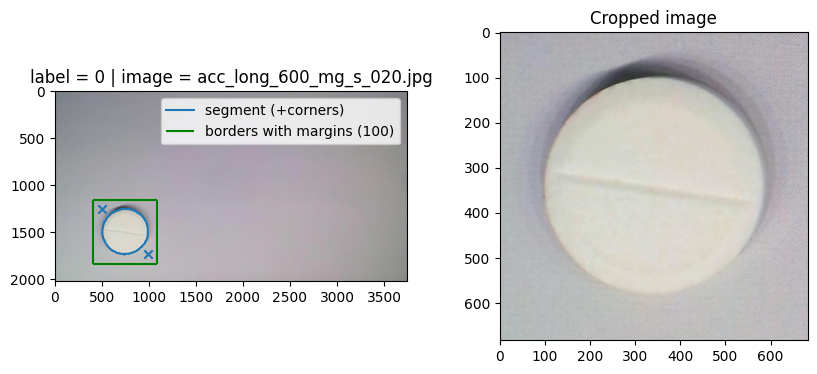

In [ ]:
# возьмем образец изображения и его описания
# - фото        - acc_long_600_mg_s_020.jpg
# - описание    - acc_long_600_mg_s_020.txt

from PIL import Image
import matplotlib.pyplot as plt
import pathlib as path


# read image
data_path = path.Path('data/dataset/sample')
image_name = 'acc_long_600_mg_s_020'
image_path = data_path / (image_name + '.jpg')
image = Image.open(image_path)

# read label and segment points
with open(data_path / (image_name + '.txt')) as f:
    label_segment = f.readline()

# plot image
plot_image_from_dataset(image, image_name, label_segment, margin=100)


 #### Подготовим датасет с обрезанными изображениями в формате задачи классификации
 Целевой формат датасет - для каждого класса своя директория, внутри которой находятся соответсвующие изображения.

```bash
uv add dotenv 
```

In [47]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm

def preprocess_dataset(src_dir, dst_dir):
    """
    Конвертация исходного Kaggle OGYEIv2 датасета к формату директорий для задачи классификации, 
    где директория соответсвует классу изображений, которые в ней находятся.
    
    При этом изображения обрезаются согласно заданному контуру в датасете, чтобы убрать выделить именно целевой объект и удалить лишний фон (или что еще лишнее могло попасть на изображение)
    """
    
    print(f'preprocess_dataset() src_dir = {src_dir}, dst_dir = {dst_dir}')

    ds_types = ['train', 'valid', 'test']
    for ds_type in ds_types:
        print(f"Processing {ds_type} split...")
        
        images_path = src_dir / ds_type / "images"
        labels_path = src_dir / ds_type / "labels"
        
        # Ensure the destination directory for this split exists
        split_dst = dst_dir / ds_type
                
        # Iterate through all label files
        for label_file in tqdm(labels_path.glob("*.txt"), ds_type):

            # Find corresponding image file
            # Try common extensions: .jpg, .jpeg, .png
            img_stem = label_file.stem
            img_file = images_path / f"{img_stem}.jpg"
                            
            if img_file is None:
                print(f"Warning: Image for {label_file.name} not found. Skipping.")
                continue

            # Open the image
            img = Image.open(img_file)
            
            # Read the label file
            with open(label_file, 'r') as f:
                line = f.readline()

            if not line:
                continue
            
            # YOLO format: <class_id> <x1> <y1> <x2> <y2> ...
            parts = line.split()
            class_id = parts[0]
            
            try:
                # Use the provided function to crop
                # We pass the whole line as label_segment
                image_crop, _, _ = parse_and_crop_image(img, line)
                
                # Create class directory: dst_dir/train/0/

                # Важно: use zfill(3) to force folder names to be lexicographically sorted - used by torchvisiion dataset ImageFolder
                class_dir = split_dst / class_id.zfill(3)

                class_dir.mkdir(parents=True, exist_ok=True)

                # Save the cropped image
                # Filename: original_name_object_index.jpg
                save_path = class_dir / img_file.name
                
                image_crop.convert("RGB").save(save_path, "JPEG")
                
            except Exception as e:
                print(f"Error processing {label_file.name}: {e}")

    print("Preprocessing complete!")

[Комментарий ревьюера] ✔️
Все верно.

In [53]:
from dotenv import load_dotenv
import os

load_dotenv()

src = os.getenv('OGYEIV2_DATASET_SRC_DIR')  # d:/AI_tools/Kaggle/datasets/richardradli/ogyeiv2/ogyeiv2/ogyeiv2
dst_dir = Path(DATASET_PATH)

# если директория еще не заполнена, то запускаем преобразование
if not any(dst_dir.iterdir()):
    if src is None:
        print('Env variable is not set (check .env) - OGYEIV2_DATASET_SRC_DIR')
    else:
        src_dir = Path(src)

    preprocess_dataset(src_dir, dst_dir)

preprocess_dataset() src_dir = d:\AI_tools\Kaggle\datasets\richardradli\ogyeiv2\ogyeiv2\ogyeiv2, dst_dir = data\dataset\ogyeiv2\parsed
Processing train split...


train: 3136it [02:47, 18.69it/s]


Processing valid split...


valid: 672it [00:36, 18.62it/s]


Processing test split...


test: 672it [00:34, 19.28it/s]

Preprocessing complete!


[Комментарий ревьюера] ⚠️
Если src is None, то src_dir не создается, но preprocess_dataset(src_dir, dst_dir) все равно вызывается.

### Подготовка и трансформация датасета

Теперь обрезанные изображения подготовлены в директории проекта `data\dataset\ogyeiv2\parsed` и разделены на выборки для обучения, валидации и тренировки 

- готовим трансформации изображений и загрузчик для подачи данных в модель
    - аугментацию (повороты, отражения) применять не нужно, так как исходные изображения и так представлены в разных ракурсах и положениях
    - выполним стандартные трансформации для подготовки изображений действия:
        - приведение к единому размеру (Resize) - 224 x 224 (это стандарт для моделей ResNet-50, mobilenet_v3)
        - масштабирование (приведение к диапазону [0,1])
        - нормализация
            - стандарт ImageNet: mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]

```bash
uv add "torchvision==0.22.0+cpu"
```

In [214]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
from torchvision.transforms.v2 import Compose, Resize, CenterCrop, ToImage, ToDtype, Normalize

# трансформации
imagenet_mean = torch.tensor([0.485, 0.456, 0.406])
imagenet_std = torch.tensor([0.229, 0.224, 0.225])
transforms = Compose([
    Resize(size=[224,224]),
    ToImage(),
    ToDtype(dtype=torch.float32, scale=True),
    Normalize(mean=list(imagenet_mean.numpy()), std=list(imagenet_std.numpy()))
])

# датасеты
dst_dir = DATASET_PATH
train_dataset = ImageFolder(dst_dir / "train", transform=transforms)
val_dataset = ImageFolder(dst_dir / "valid", transform=transforms)
test_dataset = ImageFolder(dst_dir / "test", transform=transforms)

print(f'train_dataset = {len(train_dataset)}, val_dataset = {len(val_dataset)}, test_dataset = {len(test_dataset)}')

train_dataset = 3136, val_dataset = 672, test_dataset = 672


#### Помотрим распределение изображений по классам

In [70]:
# Помотрим распределение изображений по классам

import pandas as pd

# соберем данные в pandas DataFrame и посмотрим распределение
stats_df = pd.DataFrame(train_dataset.samples, columns=['name', 'label'])
stats_df['name'] = stats_df['name'].apply(lambda name: name.split("\\")[-1])

print(f'Всего классов: {stats_df["label"].nunique()}\n')

# посмотрим распределение
label_distrib = stats_df.groupby(by='label').count().rename(columns={'name': 'count'})
print(f'Распределение таблеток по классам: \n {label_distrib.describe()}\n')

Всего классов: 111

Распределение таблеток по классам: 
             count
count  111.000000
mean    28.252252
std      2.657642
min     28.000000
25%     28.000000
50%     28.000000
75%     28.000000
max     56.000000



[Комментарий ревьюера] ⚠️
Разбиение пути по \ \ . Лучше использовать pathlib.

Результат:
- 111 классов (должно быть 112!) - один потерян
- 28 примеров на класс
- выброс на 56 примеров элементов

[Комментарий ревьюера] ✔️
хорошее наблюдение

In [74]:
# посмотрим на выбросы, у кого больше 28 изображений на класс
label_distrib[label_distrib['count'] > 28]

,count
label,
5,56


In [75]:
# видим, что в 5-м классе (метке) присутсвуют разные таблетки 
bad_cls = stats_df[stats_df['label'] == 5]
print(bad_cls.head(), '\n', bad_cls.tail())

                           name  label
140  algopyrin_500_mg_s_001.jpg      5
141  algopyrin_500_mg_s_003.jpg      5
142  algopyrin_500_mg_s_004.jpg      5
143  algopyrin_500_mg_s_005.jpg      5
144  algopyrin_500_mg_s_006.jpg      5 
                   name  label
191  cold_fx_u_015.jpg      5
192  cold_fx_u_016.jpg      5
193  cold_fx_u_017.jpg      5
194  cold_fx_u_018.jpg      5
195  cold_fx_u_019.jpg      5


Вывод по распределению по классам:
- train датасет - 28 примеров на каждый класс
- val датасет - 6 примеров на каждый класс
- test датасет - 6 примеров на каждый класс

При этом в каждом датасете есть ошибка в классе "5" - там содержаться два разных вида таблеток, например:
- algopyrin_500_mg_s_006.jpg
- cold_fx_u_015.jpg

При этом 1 класс потерян, и можно понять, что 21-ый класс, должен содержать "cold_fx", но его нет, так как его метка определена как 5-ый класс - что является ошибка в самом оригинальном датасете.

#### Исправление ошибки присвоения метки класса для "cold_fx" (было 5, должно быть 21)

In [ ]:
# Для исправления этой ситуации, перенесем перенесем все изображения с именем "cold_fx" в свой правильный класс "021"

%%cmd

# train
mkdir "data/dataset/ogyeiv2/parsed/train/021"
mv "data/dataset/ogyeiv2/parsed/train/005/cold_fx*.jpg" "data/dataset/ogyeiv2/parsed/train/021"

# valid
mkdir "data/dataset/ogyeiv2/parsed/valid/021"
mv "data/dataset/ogyeiv2/parsed/valid/005/cold_fx*.jpg" "data/dataset/ogyeiv2/parsed/valid/021"

# test
mkdir "data/dataset/ogyeiv2/parsed/test/021"
mv "data/dataset/ogyeiv2/parsed/test/005/cold_fx*.jpg" "data/dataset/ogyeiv2/parsed/test/021"


#### Пересобираем датасеты

In [215]:
# датасеты
dst_dir = DATASET_PATH
train_dataset = ImageFolder(dst_dir / "train", transform=transforms)
val_dataset = ImageFolder(dst_dir / "valid", transform=transforms)
test_dataset = ImageFolder(dst_dir / "test", transform=transforms)

print(f'train_dataset = {len(train_dataset)}, val_dataset = {len(val_dataset)}, test_dataset = {len(test_dataset)}')

# загрузчики
init_random()
batch_size = 32
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size)

train_dataset = 3136, val_dataset = 672, test_dataset = 672


In [78]:
# Проверяем, что распределение теперь не содержит выбросов

import pandas as pd

for ds_name, ds in {'train': train_dataset, 'val': val_dataset, 'test': test_dataset}.items():
    # соберем данные в pandas DataFrame и посмотрим распределение
    stats_df = pd.DataFrame(ds.samples, columns=['name', 'label'])
    stats_df['name'] = stats_df['name'].apply(lambda name: name.split("\\")[-1])

    print(f'{ds_name}: Всего классов: {stats_df["label"].nunique()}\n')

    # посмотрим распределение
    label_distrib = stats_df.groupby(by='label').count().rename(columns={'name': 'count'})
    print(f'{ds_name}: Распределение таблеток по классам: \n {label_distrib.describe()}\n')

train: Всего классов: 112

train: Распределение таблеток по классам: 
        count
count  112.0
mean    28.0
std      0.0
min     28.0
25%     28.0
50%     28.0
75%     28.0
max     28.0

val: Всего классов: 112

val: Распределение таблеток по классам: 
        count
count  112.0
mean     6.0
std      0.0
min      6.0
25%      6.0
50%      6.0
75%      6.0
max      6.0

test: Всего классов: 112

test: Распределение таблеток по классам: 
        count
count  112.0
mean     6.0
std      0.0
min      6.0
25%      6.0
50%      6.0
75%      6.0
max      6.0



Теперь ошибка исправлена по всем сплитам датасета:
- количестово классов 112
- распределение объектов по классам равномерное - 28 / 6 / 6

### Проверка, что данные читаются и корректно трансформируются

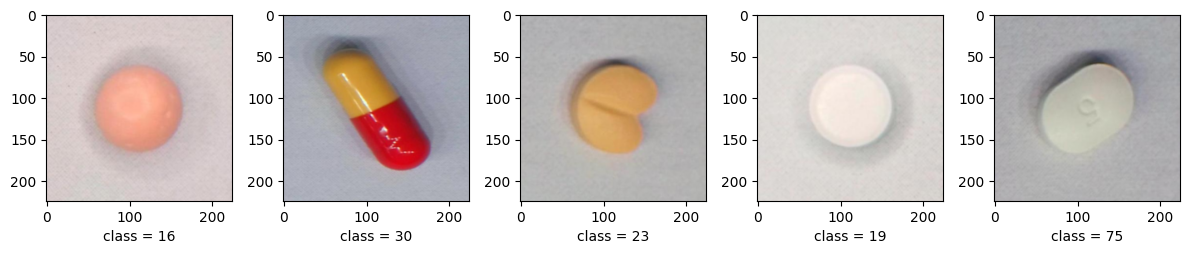

In [216]:
# пример данных
init_random()
sample_batch = next(iter(train_loader))
sample_batch_images= sample_batch[0]
sample_batch_labels = sample_batch[1]

plt.figure(figsize=(12,3))
for i in range(5):
    img = sample_batch_images[i]
    class_label = sample_batch_labels[i].item()

    # денормализация для возврата в диапазон [0,1]
    img = img * imagenet_std.view(3,1,1) + imagenet_mean.view(3,1,1)

    plt.subplot(1,5,i+1)
    plt.imshow(img.permute(1,2,0)); plt.xlabel(f'class = {class_label}')

plt.tight_layout()

### Результат этапа
- данные загружены с сайта Kaggle, так как Яндекс Диск не доступен, данные представлены в формате YOLO для сегментации
- выполнено преобразование Kaggle-датасета в формат задачи классификации:
    - фотографии обрезаны согласно заданному контуру - это сильно снизило размер изображения и оставило на фото только саму таблетку, без лишнего фона и всего остального что могло быть на оригинальном фото
    - изображения перенесены в стандартную структуру директорий - название соответствует классу изображений, которые в ней содержатся
- обнаружена ошибка в исходном датасете по распределению изображений по классам:
    - таблетки "cold_fx" имели ошибочную метку "5", и находились вместе с правильными таблетками "algopyrin"
    - по этой причине, также был пропущен класс "21" для "cold_fx" - что показывало количество классов 111, а должно быть 112 согласно описанию датасета и представленным классам
- ошибка исправлена, теперь распределение корректное
    - количество классов 112
    - распределение объектов по классам равномерное - 28 / 6 / 6

## Этап 2 - Объявление модели
- Создать классификатор, подходящий для задачи, если часть весов нужно заморозить, сделайте это

Попробуем использовать стандартную предобученную модель ResNet-50 и заменим последний слой классификатора, для выдачи результата на 112 классов

```bash
uv add torchsummary
```

In [114]:
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from torchsummary import summary

model =  mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)

print(f'Original last classifier layer = {model.classifier}')
summary(model, input_size=(3,224,224))

Original last classifier layer = Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 112, 112]             432
       BatchNorm2d-2         [-1, 16, 112, 112]              32
         Hardswish-3         [-1, 16, 112, 112]               0
            Conv2d-4           [-1, 16, 56, 56]             144
       BatchNorm2d-5           [-1, 16, 56, 56]              32
              ReLU-6           [-1, 16, 56, 56]               0
 AdaptiveAvgPool2d-7             [-1, 16, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             136
              ReLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 16, 1, 1]             144
      

Данные исходной модели mobilenet_v3_small:
- количество обучаемых параметров: 2,542,856

>```
>... <skip conv layers>
>          Linear-161                 [-1, 1000]       1,025,000
>================================================================
>Total params: 2,542,856
>Trainable params: 2,542,856
>Non-trainable params: 0
>----------------------------------------------------------------
>Input size (MB): 0.57
>Forward/backward pass size (MB): 34.61
>Params size (MB): 9.70
>Estimated Total Size (MB): 44.88
>----------------------------------------------------------------
>```

In [217]:
# Заменяем последний линейный слой `fc` и замораживаем все веса кроме этого слоя

import torch.nn as nn

# меняем выходной слой
model.classifier = nn.Sequential(
    nn.Linear(in_features=576, out_features=112)
)

# замораживаем веса
for p in model.parameters():
    p.requires_grad = False

# размораживаем веса последнего слоя
for p in model.classifier.parameters():
    p.requires_grad = True

print(f'Modified last classifier layer = {model.classifier}')

summary(model, input_size=(3,224,224))

Modified last classifier layer = Sequential(
  (0): Linear(in_features=576, out_features=112, bias=True)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 112, 112]             432
       BatchNorm2d-2         [-1, 16, 112, 112]              32
         Hardswish-3         [-1, 16, 112, 112]               0
            Conv2d-4           [-1, 16, 56, 56]             144
       BatchNorm2d-5           [-1, 16, 56, 56]              32
              ReLU-6           [-1, 16, 56, 56]               0
 AdaptiveAvgPool2d-7             [-1, 16, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             136
              ReLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 16, 1, 1]             144
      Hardsigmoid-11             [-1, 16, 1, 1]               0
SqueezeExcitation-12           [-1, 16, 56, 56]             

[Комментарий ревьюера] ✔️
Заморозка весов + проверка через summary()

Данные модели `mobilenet_v3_small` подготовленной для обучения на задачую классификации на 112 классов:
- количество обучаемых параметров = 64,624

>```
>... <skip conv layers>
>          Linear-158                  [-1, 112]          64,624
>================================================================
>Total params: 991,632
>Trainable params: 64,624
>Non-trainable params: 927,008
>----------------------------------------------------------------
>Input size (MB): 0.57
>Forward/backward pass size (MB): 34.58
>Params size (MB): 3.78
>Estimated Total Size (MB): 38.94
>----------------------------------------------------------------
>```

### Результат этапа
Выполнено:
- создан классификатор `mobilenet_v3_small` с предобученными весами IMAGENET1K_V1
- заменен последний линейный слой для 112 классов
- заморожены веса, кроме последнего слоя
- количество обучаемых параметров = 64,624

## Этап 3 - Обучение или дообучение
- дообучить классификатор, сохранить модель в файл `meds_classifier.pt`
- предусмотрить вариант обучения на `GPU` (`cuda`) - НЕ АКТУАЛЬНО, т.к. ВМ с GPU недоступна
- обучать модель до получения метрики точности 75%
**Результат**:
	- распечатка ошибок на обучающем и тестовом датасете в конце каждой эпохи
	- файл с моделью - `meds_classifier.pt`


```bash
uv add "scikit-learn==1.6.1"
```

In [218]:
import torch, torch.optim as optim, torch.nn as nn
from tqdm import tqdm
from sklearn.metrics import accuracy_score

# Настройка гиперпараметров
learning_rate = 0.01
optimizer = optim.Adam(params=model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()
EPOCHS = 50

# функция обучения для одной эпохи
def train_one_epoch(epoch_index):
    """
    Выполнение цикла обучения одной эпохи
    """

    running_loss = 0

    model.train()
    for i, data in tqdm(enumerate(train_loader), 'train'):
        x, label = data

        optimizer.zero_grad()
        
        out = model(x)
        loss = criterion(out,label)
        loss.backward()
        optimizer.step()
    
        running_loss += loss.item()

        # if i % 30 == 0:
        #     print(f'{i}: running_loss avg = {running_loss/(i+1):.2f}')

        # if i == 5:
        #     break
            
    return running_loss/(i+1)

# запус обучения

ACCURACY_TARGET = 0.75

train_loss_history = []
val_loss_history = []
val_acc_history = []

best_loss = 1e3
for epoch in range(EPOCHS):

    # Ваш код для проведения эпохи обучения
    # и подсчёта ошибки на валидации
    avg_loss = train_one_epoch(epoch)
    train_loss_history.append(avg_loss)

    running_loss = 0.
    model.eval()

    labels_predicted = []
    labels_true = []

    for i, data in tqdm(enumerate(val_loader), 'val'):
        x, labels = data

        with torch.no_grad():
            logits = model(x)
            loss = criterion(logits, labels)
            running_loss += loss.item()

            pred_label = torch.argmax(logits, dim=1)
            labels_predicted.extend(pred_label.numpy())
            labels_true.extend(labels.numpy())

        # if i == 5:
        #     break
       
    avg_vloss = running_loss/(i+1)
    accouracy = accuracy_score(labels_true, labels_predicted)
    
    val_loss_history.append(avg_loss)
    val_acc_history.append(accouracy)

    print(f'Эпоха {epoch}: ошибка train = {avg_loss:.6f}, ошибка val = {avg_vloss:.6f}, accouracy = {accouracy:.2%}')

    # сохранение лучшей версии модели
    if avg_vloss < best_loss:
        model_path = MODELS_PATH / f'meds_classifier_{epoch}.pt'
        best_loss = avg_vloss
        
        torch.save(model.state_dict(), model_path)
        pd.Series(train_loss_history).to_csv(MODELS_PATH/'train_loss_history.csv')
        pd.Series(val_loss_history).to_csv(MODELS_PATH/'val_loss_history.csv')
        pd.Series(val_acc_history).to_csv(MODELS_PATH/'val_acc_history.csv')

    if accouracy >= ACCURACY_TARGET*1.1:
        print(f'target accuracy reached!, stop learning - accouracy = {accouracy}')
        break

train: 98it [00:27,  3.51it/s]
val: 21it [00:05,  4.17it/s]


Эпоха 0: ошибка train = 2.643019, ошибка val = 1.063874, accouracy = 71.13%


train: 98it [00:26,  3.64it/s]
val: 21it [00:04,  4.20it/s]


Эпоха 1: ошибка train = 0.764130, ошибка val = 0.787747, accouracy = 79.61%


train: 98it [00:27,  3.61it/s]
val: 21it [00:05,  4.17it/s]


Эпоха 2: ошибка train = 0.529061, ошибка val = 0.637886, accouracy = 81.55%


train: 98it [00:26,  3.63it/s]
val: 21it [00:04,  4.20it/s]

Эпоха 3: ошибка train = 0.347163, ошибка val = 0.556635, accouracy = 84.67%
target accuracy reached!, stop learning - accouracy = 0.8467261904761905


[Комментарий ревьюера] ⚠️
Лучше сохранять лучшую модель в фиксированный путь.

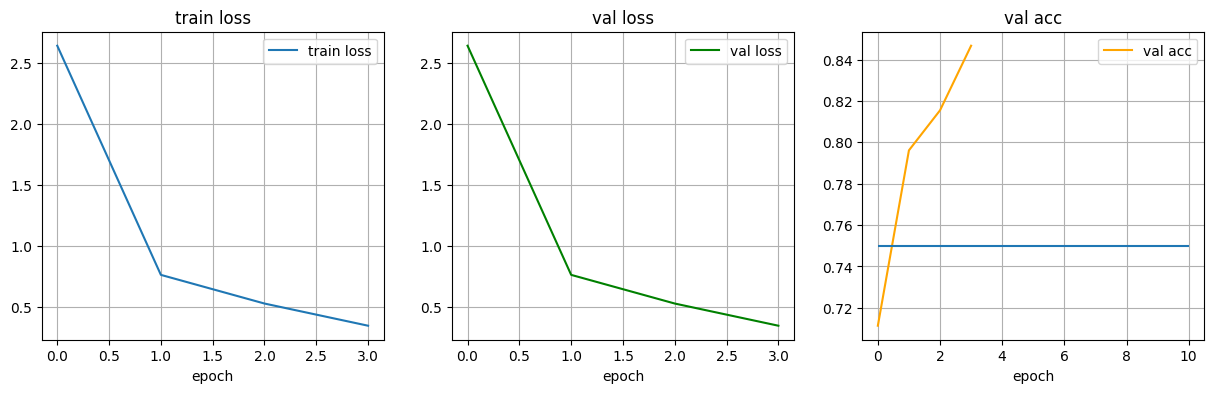

In [219]:
fig, axs = plt.subplots(1,3, figsize=(15,4))
ax = axs[0]
f = ax.plot(train_loss_history); 
ax.set_title('train loss');ax.grid();ax.set_xlabel('epoch');l = ax.legend(['train loss'])
ax = axs[1]
f = ax.plot(val_loss_history, color='green') 
ax.set_title('val loss');ax.grid();ax.set_xlabel('epoch');l = ax.legend(['val loss'])
ax = axs[2]
f = ax.plot(val_acc_history, color='orange')
ax.set_title('val acc');ax.grid();ax.set_xlabel('epoch');l = ax.legend(['val acc'])
plt.hlines(y=0.75, xmin=0, xmax=10)

### Результат этапа
- модель `mobilenet_v3_small` обучена в течение 4 эпох, достигнуто превышение целевой метрики точности в 75% - получено превышение на 10% - 84.67%
- актуальная модель (точнее веса) сохранены
- данные обучения залогированы и сохранены
- графики обучения и точности выведены
    
P.S. первичная попытка обучить ResNet-50 заняла бы в 100 раз большее время, и на удивление `mobilenet_v3_small` обучилась очень быстро на lr=0.01

## Этап 4 - Оценка качества
- рассчитать метрики обученного классификатора используя проверочный датасет
- выведите метрики для каждого класса (precision, recall, f1) и accuracy

### Выполнение предсказаний на тестовом датасете

In [ ]:
from sklearn.metrics import classification_report
import torch

# загрузим модель и обученные веса
model = mobilenet_v3_small()
# меняем выходной слой
model.classifier = nn.Sequential(
    nn.Linear(in_features=576, out_features=112)
)

final_model_weights = MODELS_PATH / "meds_classifier_3.pt"
model.load_state_dict(torch.load(final_model_weights, weights_only=True))

labels_predicted = []
labels_true = []

# выполняем предсказания на тестовом датасете
model.eval()
for i, data in tqdm(enumerate(test_loader), 'test'):
    x, labels = data
    with torch.no_grad():
        logits = model(x)
        pred_label = torch.argmax(logits, dim=1)

        labels_predicted.extend(pred_label.numpy())
        labels_true.extend(labels.numpy())

# формируем отчет по точности
print(classification_report(labels_true, labels_predicted, zero_division=0)) # type: ignore

test: 21it [00:05,  3.94it/s]

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         6
           2       1.00      0.67      0.80         6
           3       1.00      1.00      1.00         6
           4       1.00      1.00      1.00         6
           5       0.67      1.00      0.80         6
           6       1.00      0.83      0.91         6
           7       1.00      1.00      1.00         6
           8       1.00      1.00      1.00         6
           9       1.00      1.00      1.00         6
          10       0.45      0.83      0.59         6
          11       0.56      0.83      0.67         6
          12       1.00      1.00      1.00         6
          13       1.00      1.00      1.00         6
          14       1.00      1.00      1.00         6
          15       1.00      1.00      1.00         6
          16       1.00      1.00      1.00         6
          17       1.00    

### Топ-5 классов с наихудшей оценкой

In [ ]:
# выбираем 5 классов с наименьшей точностью

report = classification_report(labels_true, labels_predicted, zero_division=0, output_dict=True)
report = pd.DataFrame(report).T

min_precision_top_5 = report.sort_values(by=['precision']).head()
print(f'min_precision_top_5: \n{min_precision_top_5}')


min_precision_top_5: 
    precision    recall  f1-score  support
86   0.000000  0.000000  0.000000      6.0
93   0.250000  0.166667  0.200000      6.0
39   0.307692  0.666667  0.421053      6.0
43   0.400000  0.666667  0.500000      6.0
89   0.416667  0.833333  0.555556      6.0


true label= 86, pred = tensor([84]), preds = tensor([0.1931, 0.1683, 0.1332, 0.0806, 0.0499]), indices = tensor([84, 89, 68, 60, 33])
true label= 93, pred = tensor([68]), preds = tensor([0.8557, 0.0377, 0.0203, 0.0173, 0.0152]), indices = tensor([68, 39, 85, 93, 10])
true label= 39, pred = tensor([39]), preds = tensor([0.6450, 0.0894, 0.0528, 0.0301, 0.0295]), indices = tensor([39, 42, 40, 37, 32])
true label= 43, pred = tensor([110]), preds = tensor([0.3773, 0.3572, 0.1251, 0.0326, 0.0260]), indices = tensor([110,  43,  33,  38,  12])
true label= 89, pred = tensor([89]), preds = tensor([0.3558, 0.1737, 0.1425, 0.0507, 0.0474]), indices = tensor([89, 43, 47, 66, 79])


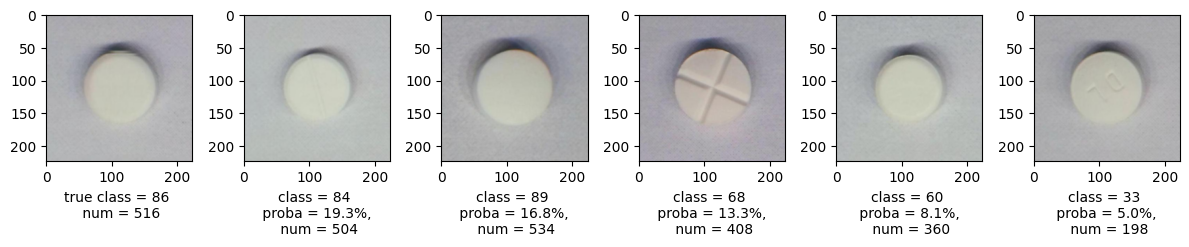

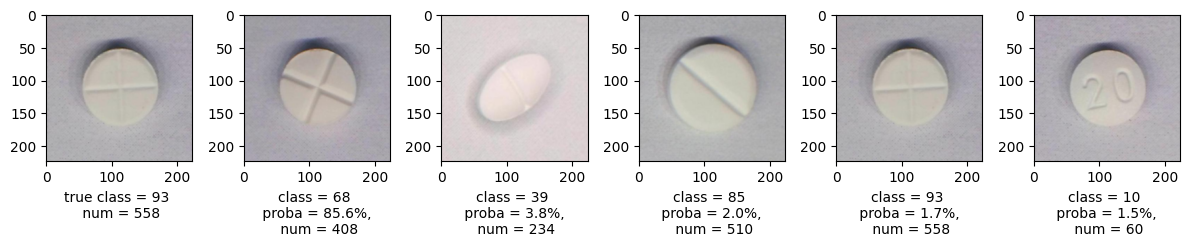

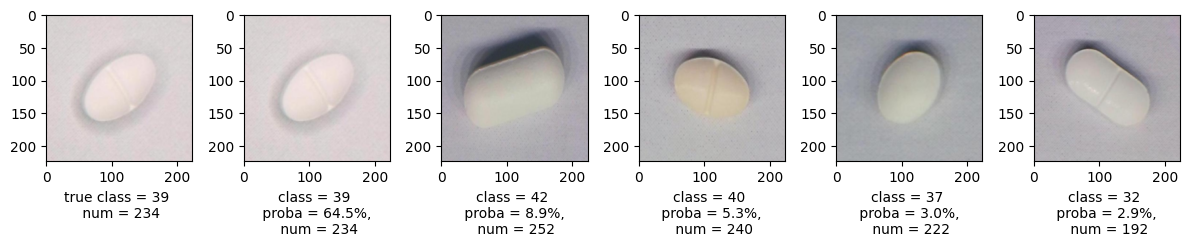

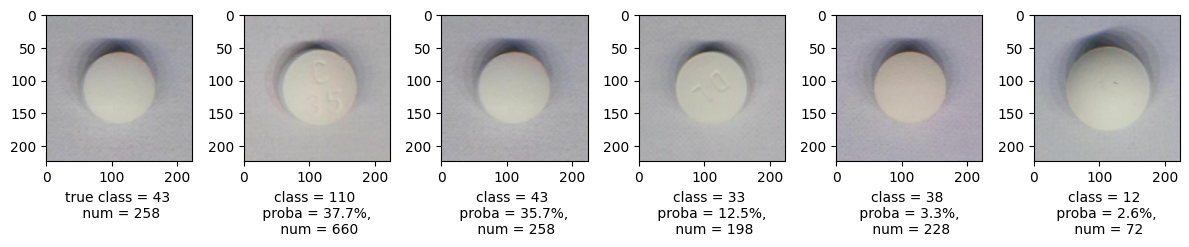

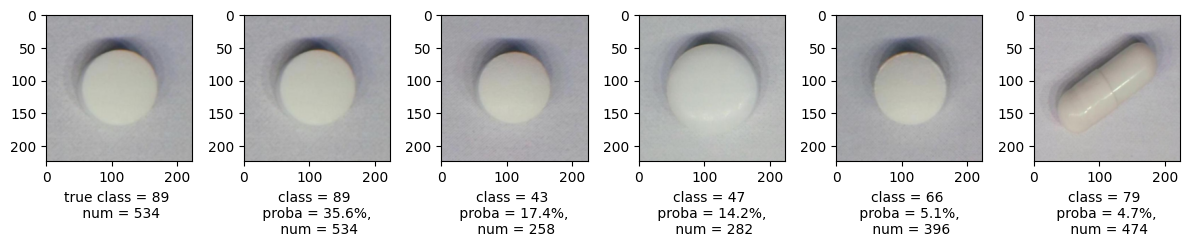

In [231]:
# посмотрим как выглядят классы, на которах модель сильнее всего ошибалась

def show_pediction(class_label):
    """
    Вывод верной картинки + топ-5 предсказаний модели для визуальной проверки, почему модель ошибается
    """

    # выбираем первую картинку этого класса в тестовом датасете
    img_num = class_label*6
    x, label = test_dataset[img_num]

    # выполняем предсказание
    with torch.no_grad():
        logits = model(x.unsqueeze(dim=0))
        
        # вычисляем вероятности классов (уверенность модели)
        probas = nn.functional.softmax(logits, dim=1)
        pred = torch.argmax(probas, dim=1)
        
        # берем топ-5
        preds, indices = torch.topk(probas, 5, dim=1)
        preds = preds[0]
        indices = indices[0]

        print(f'true label= {label}, pred = {pred}, preds = {preds}, indices = {indices}')

        # выводим изображения
        plt.figure(figsize=(12,3))
        plt.subplot(1,6,1)
        img = x * imagenet_std.view(3,1,1) + imagenet_mean.view(3,1,1)
        plt.imshow(img.permute(1,2,0)); plt.xlabel(f'true class = {label} \n num = {img_num}')

        for i in range(5):
            pred_img_num = int(indices[i])*6
            pred_x, pred_label = test_dataset[pred_img_num]    
            
            # денормализация для возврата в диапазон [0,1]
            pred_img = pred_x * imagenet_std.view(3,1,1) + imagenet_mean.view(3,1,1)

            plt.subplot(1,6,i+2)
            plt.imshow(pred_img.permute(1,2,0)); plt.xlabel(f'class = {pred_label} \n proba = {preds[i]:.1%}, \n num = {pred_img_num}')

        plt.tight_layout()

# посмотрим как выглядят ошибочные классы
# класс 86 - 0% точность
show_pediction(86)

# класс 93 - 25% точность
show_pediction(93)

# класс 39 - 30% точность
show_pediction(39)

# класс 43 - 40% точность
show_pediction(43)

# класс 89 - 41% точность
show_pediction(89)

[Комментарий ревьюера] ✔️
Визуальный разбор ошибок

### Топ классов с наилучшей оценкой

In [ ]:
# выбираем классы с максимальной точностью

max_precision = report.sort_values(by=['f1-score'], ascending=False).head(5)
print(f'max_precision: \n{max_precision}')


max_precision: 
    precision  recall  f1-score  support
0         1.0     1.0       1.0      6.0
1         1.0     1.0       1.0      6.0
3         1.0     1.0       1.0      6.0
17        1.0     1.0       1.0      6.0
4         1.0     1.0       1.0      6.0


true label= 0, pred = tensor([0]), preds = tensor([9.9753e-01, 1.4450e-03, 9.1348e-04, 7.6590e-05, 1.0568e-05]), indices = tensor([ 0,  5, 31, 85, 33])
true label= 1, pred = tensor([1]), preds = tensor([0.7532, 0.1939, 0.0221, 0.0215, 0.0058]), indices = tensor([  1, 103,  34, 109,   4])
true label= 3, pred = tensor([3]), preds = tensor([9.9788e-01, 6.2622e-04, 6.0021e-04, 3.6348e-04, 1.6332e-04]), indices = tensor([ 3, 90, 15, 44,  4])
true label= 17, pred = tensor([17]), preds = tensor([0.6371, 0.2242, 0.0274, 0.0223, 0.0181]), indices = tensor([17, 27, 87, 10, 99])
true label= 4, pred = tensor([4]), preds = tensor([9.9979e-01, 1.3209e-04, 6.0940e-05, 6.6807e-06, 6.5220e-06]), indices = tensor([  4,  62,  30,   1, 109])


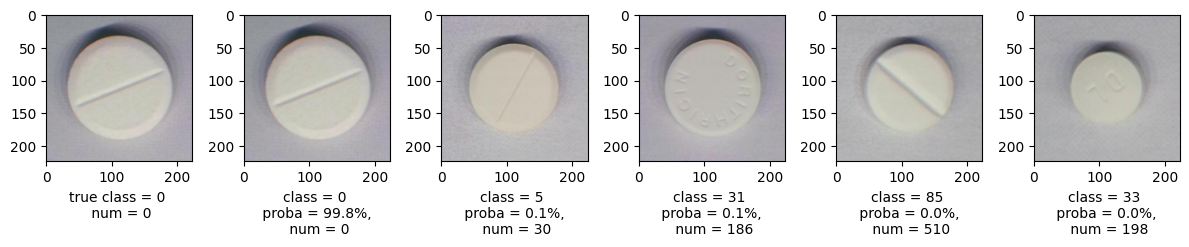

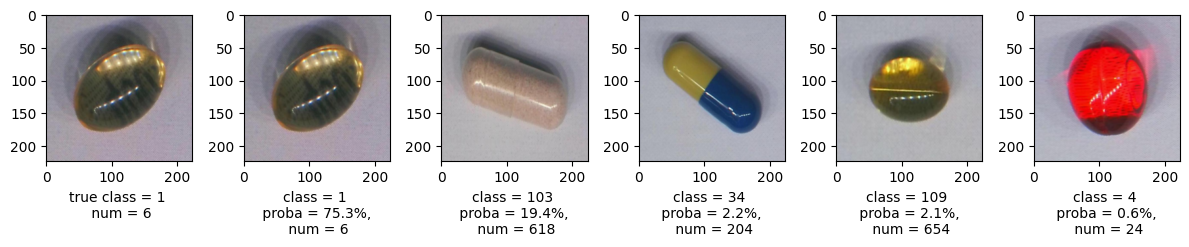

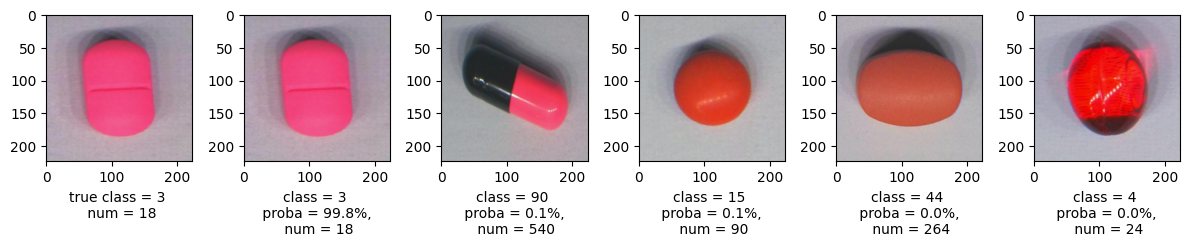

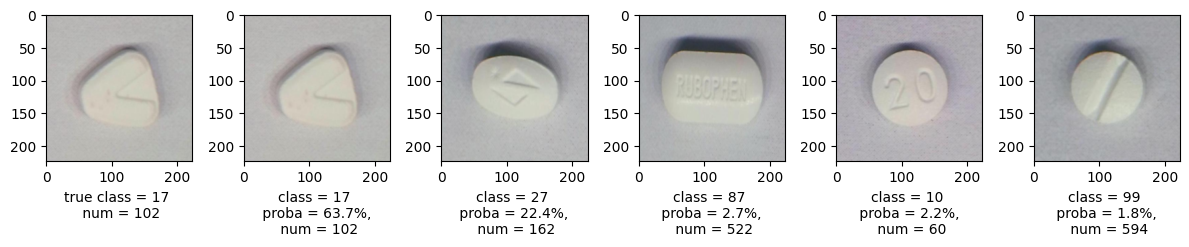

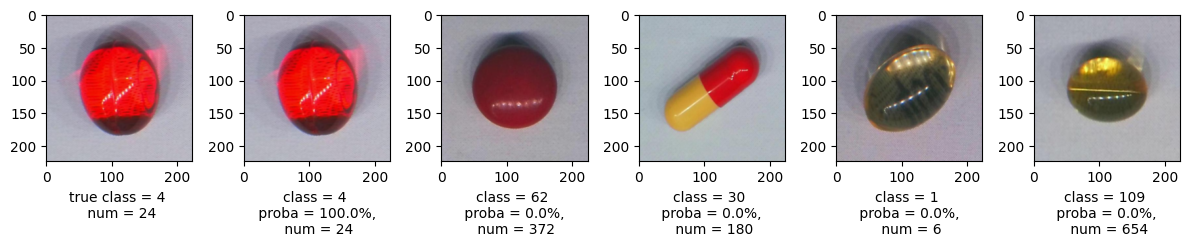

In [235]:
# посмотрим как выглядят классы со 100%-ой точностью
# класс 0 - 100% точность
show_pediction(0)

# класс 1 - 100% точность
show_pediction(1)

# класс 3 - 100% точность
show_pediction(3)

# класс 17 - 100% точность
show_pediction(17)

# класс 4 - 100% точность
show_pediction(4)

### Построим матрицу ошибок (Confustion matrix)
- матрица ошибок может показать в какие классы модель делала ложные предсказания

```bash
uv add seaborn
```

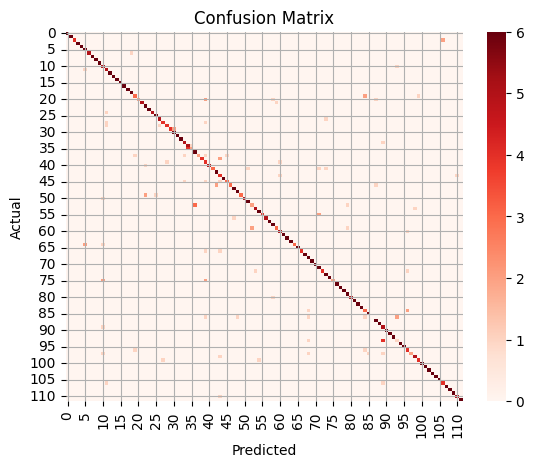

In [243]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_report = confusion_matrix(labels_true, labels_predicted)
sns.heatmap(cm_report, cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.grid()
t=plt.title('Confusion Matrix')

### Результат этапа
- рассчитаны метрики точности на тестовом датасете - результат 85%
- ответы на вопросы:
    - На каких 5 классах модель ошибается чаще всего?
        - класс 86 - 0% точность
        - класс 93 - 25% точность
        - класс 39 - 30% точность
        - класс 43 - 40% точность
        - класс 89 - 41% точность
        
    - Почему модель может ошибаться на этих классах?
        - глядя на фото образцов, на которых модель имеет наименьшую точность - очевидно очень сложно правильно определить результат, так это примитивные объекты - "круглая белая таблетка", которая очень похожа на другие такие же "круглые белые таблетки"
    
    - На каких классах модель не совершает ошибок?
        - класс 1 - 100% точность
        - класс 3 - 100% точность
        - класс 17 - 100% точность
        - класс 4 - 100% точность

    - Почему эти классы модель распознаёт безошибочно?
        - тут ярко видны характерные особенности, которые уникальны для данного класса

    - Как можно улучшить точность классификатора?
        - можно добавить количество итераций обучения, т.к. модель явно не дошла до своего предела
        - можно усилить (усложнить) финальный слой классифкатора, сделав его 2-х слойным например

    - Как ещё можно проанализировать результаты и ошибки модели?
        - построить матрицу ошибок 
            - покажет в какие классы модель делала ложные предсказания
            - проанализировать если ли логика совершать такие ошибки, или модель совершает непонятные действия (недообучилась?)
    

[Комментарий ревьюера] ✔️
Принято

[Комментарий ревьюера] ✔️
Ты разобрался с YOLO-сегментацией и корректно вырезал объекты по полигону, собрал структуру директорий под ImageFolder, предусмотрел zfill(3) для правильной сортировки классов, провел визуальную проверку предобработки. Грамотно подошел к выбору модели, заморозил веса через requires_grad и проверил результат через summary(), а после обучения построил confusion matrix и визуальный разбор худших классов с топ-5 предсказаний.

Для улучшения работы рекомендую вынести препроцессинг и перенос классов в отдельные скрипты с проверкой входных данных, сохранять best-модель в фиксированный путь, логировать train/val метрики без хардкодов и добавить argparse или конфиг для гиперпараметров.